# Jour 5 — Stratégie marketing Superstore

Consignes : [Octopus](https://octopus.developers.institute/courses/collection/254/course/812/section/1712/chapter/4006), consultées le 29 octobre 2026. Solutions standards uniquement.

Exécuter toutes les cellules dans l’ordre ; installer les dépendances de `Week2/requirements.txt` si nécessaire.

In [1]:
from pathlib import Path
from urllib.parse import quote
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
# Chaque notebook fonctionne seul, y compris dans Colab ; données publiques du cours.
def course_file(repo, path, member=None):
    cache = Path("data"); cache.mkdir(exist_ok=True)
    destination = cache / (member or Path(path).name)
    if not destination.exists():
        suffix = quote(path)
        response = requests.get(f"https://media.githubusercontent.com/media/devtlv/{repo}/main/{suffix}", timeout=180)
        if response.status_code == 404:
            response = requests.get(f"https://raw.githubusercontent.com/devtlv/{repo}/main/{suffix}", timeout=180)
        response.raise_for_status()
        payload = response.content
        if member:
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                matches = [x for x in archive.namelist() if Path(x).name == member and not x.startswith("__MACOSX")]
                if len(matches) != 1: raise ValueError(f"Membre ambigu ou absent : {member}")
                payload = archive.read(matches[0])
        destination.write_bytes(payload)
    return destination


## Préparation
Les lignes sont des articles de commandes ; Order ID peut donc se répéter légitimement. Suppression des doublons exacts seulement. Les dates sont converties et les codes postaux restent des identifiants. Les marges agrégées sont somme(Profit)/somme(Sales), sans moyenne non pondérée des marges de lignes.

In [2]:
df = pd.read_excel(course_file("Datasets-DA-Bootcamp-2-", "Week 5 - Data Processing/W5D5 - Mini-project - bis/US Superstore data.xls"))
print("Avant nettoyage", df.shape, "doublons", df.duplicated().sum())
display(df.isna().sum().to_frame("manquants"))
df = df.drop_duplicates().copy()
for col in ["Order Date", "Ship Date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")
# Les codes postaux sont des identifiants ; une absence ne signifie pas zéro.
df["Postal Code"] = df["Postal Code"].astype("Int64").astype("string").str.zfill(5)
assert df[["Sales", "Profit", "Order Date"]].notna().all().all()
df["Profit Margin"] = df["Profit"].div(df["Sales"].replace(0,np.nan))*100
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Month"] = df["Order Date"].dt.to_period("M")
print("Après nettoyage",df.shape)
display(df.head())

Avant nettoyage (9994, 21) doublons 0


/var/folders/tn/21t5tzkd48z82_wfylsc12l00000gn/T/ipykernel_55768/4250579115.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(course_file("Datasets-DA-Bootcamp-2-", "Week 5 - Data Processing/W5D5 - Mini-project - bis/US Superstore data.xls"))


,manquants
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Après nettoyage (9994, 25)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Profit Margin,Order Year,Order Month,Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,16.00,2016,11,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,30.00,2016,11,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,47.00,2016,6,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,-40.00,2015,10,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,11.25,2015,10,2015-10


## États : ventes, profit et marges

,Sales,Profit,MarginPct
State,,,
California,457687.6315,76381.3871,16.688541
New York,310876.2710,74038.5486,23.816082
Texas,170188.0458,-25729.3563,-15.118192
Washington,138641.2700,33402.6517,24.092863
Pennsylvania,116511.9140,-15559.9603,-13.354823
Florida,89473.7080,-3399.3017,-3.799219
Illinois,80166.1010,-12607.8870,-15.727205
Ohio,78258.1360,-16971.3766,-21.686405
Michigan,76269.6140,24463.1876,32.074618


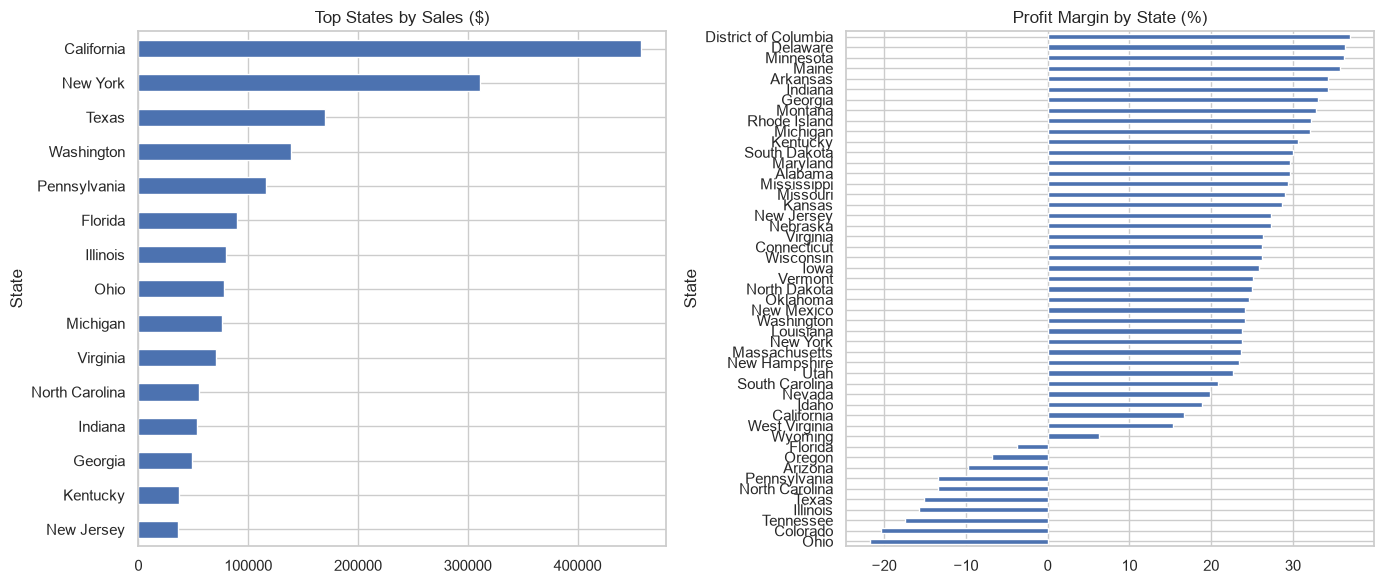

,Sales,Profit,MarginPct
State,,,
New York,310876.2710,74038.5486,23.816082
California,457687.6315,76381.3871,16.688541


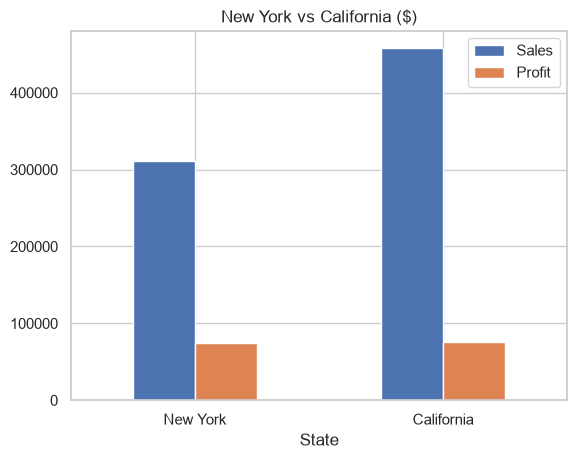

Différence Californie - New York {'Sales': 146811.3605, 'Profit': 2342.838499999998, 'MarginPct': -7.127541519514914}


In [3]:
states=df.groupby("State")[["Sales","Profit"]].sum().sort_values("Sales",ascending=False)
states["MarginPct"]=100*states["Profit"]/states["Sales"]
display(states)
fig,axes=plt.subplots(1,2,figsize=(14,6))
states["Sales"].head(15).sort_values().plot.barh(ax=axes[0],title="Top States by Sales ($)")
states["MarginPct"].sort_values().plot.barh(ax=axes[1],title="Profit Margin by State (%)")
plt.tight_layout();plt.show()
compare=states.loc[["New York","California"]];display(compare)
compare[["Sales","Profit"]].plot.bar(title="New York vs California ($)");plt.xticks(rotation=0);plt.show()
print("Différence Californie - New York",(compare.loc["California"]-compare.loc["New York"]).to_dict())

## Client remarquable à New York
Le critère retenu est le profit total, puis on donne aussi le leader en ventes. L’identifiant client évite de confondre les homonymes.

,,Sales,Profit
Customer ID,Customer Name,,
TA-21385,Tom Ashbrook,13723.498,4599.2073
KD-16495,Keith Dawkins,5854.194,2510.8903
KD-16270,Karen Daniels,6241.282,2283.0463
NM-18445,Nathan Mautz,4821.292,2247.1904
TB-21400,Tom Boeckenhauer,6999.960,2239.9872
SR-20740,Steven Roelle,3904.680,1863.9614
PK-19075,Pete Kriz,4816.690,1695.3209
DM-13015,Darrin Martin,4283.792,1599.6806
TS-21370,Todd Sumrall,6492.314,1574.9714


Leader profit NY ('TA-21385', 'Tom Ashbrook') 4599.207299999999
Leader ventes NY ('TA-21385', 'Tom Ashbrook') 13723.498000000001


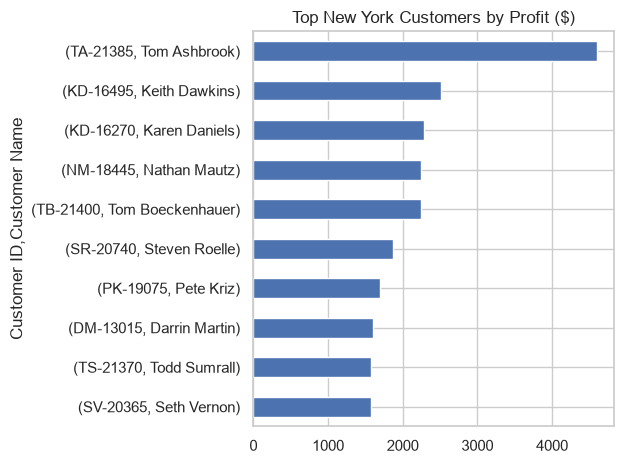

In [4]:
ny=df.loc[df["State"].eq("New York")].groupby(["Customer ID","Customer Name"])[["Sales","Profit"]].sum()
display(ny.sort_values("Profit",ascending=False).head(10))
print("Leader profit NY",ny["Profit"].idxmax(),ny["Profit"].max())
print("Leader ventes NY",ny["Sales"].idxmax(),ny["Sales"].max())
ny["Profit"].nlargest(10).sort_values().plot.barh(title="Top New York Customers by Profit ($)");plt.tight_layout();plt.show()

## Pareto des clients : profit et ventes
On trie tous les clients par métrique décroissante et calcule la part du top ceil(20 %). Pour le profit net, les clients déficitaires peuvent faire dépasser 100 % de contribution cumulée ; on conserve ces pertes pour ne pas fausser le dénominateur.

Profit clients 793 top20 effectif 159 contribution 81.66% clients nécessaires à 80% 153 (19.29%)
Sales clients 793 top20 effectif 159 contribution 48.15% clients nécessaires à 80% 396 (49.94%)


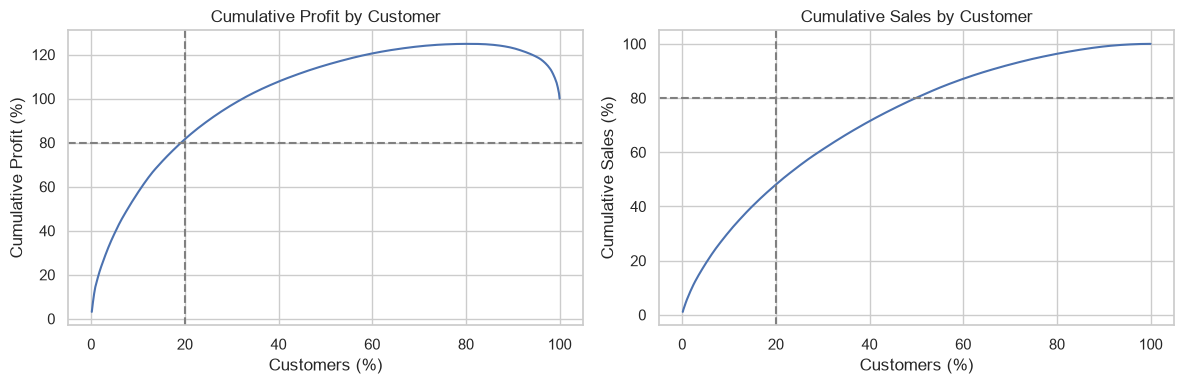

,,Sales,Profit
Customer ID,Customer Name,,
SM-20320,Sean Miller,25043.050,-1980.7393
TC-20980,Tamara Chand,19052.218,8981.3239
RB-19360,Raymond Buch,15117.339,6976.0959
TA-21385,Tom Ashbrook,14595.620,4703.7883
AB-10105,Adrian Barton,14473.571,5444.8055
KL-16645,Ken Lonsdale,14175.229,806.8550
SC-20095,Sanjit Chand,14142.334,5757.4119
HL-15040,Hunter Lopez,12873.298,5622.4292
SE-20110,Sanjit Engle,12209.438,2650.6769


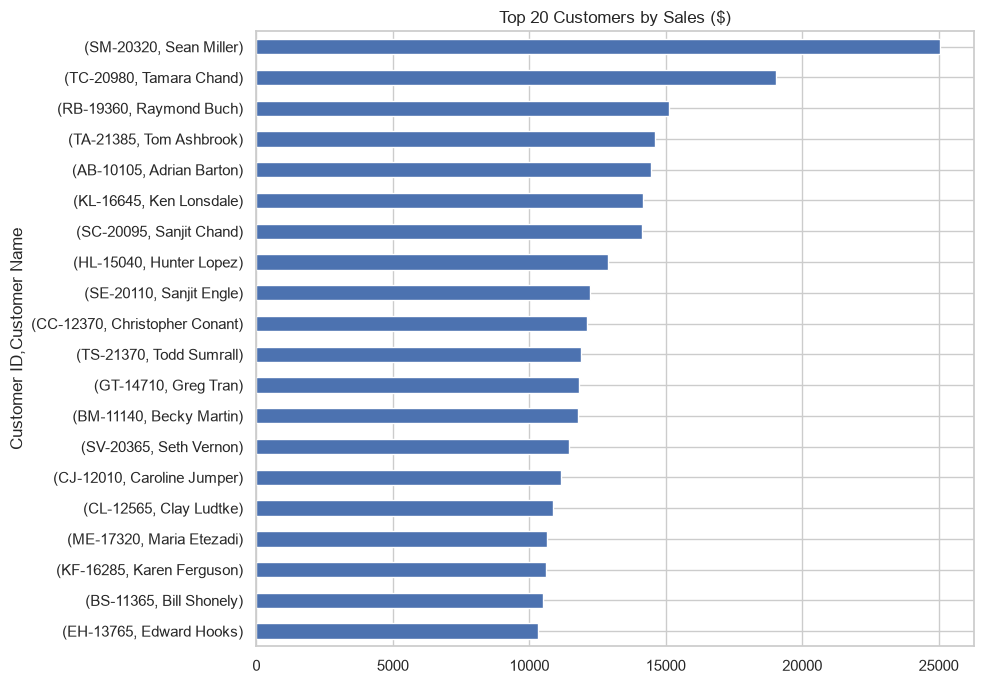

In [5]:
customers=df.groupby(["Customer ID","Customer Name"])[["Sales","Profit"]].sum()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,["Profit","Sales"]):
    values=customers[metric].sort_values(ascending=False)
    cumulative=values.cumsum()/values.sum();fraction=np.arange(1,len(values)+1)/len(values)
    k=int(np.ceil(.2*len(values)));share=values.iloc[:k].sum()/values.sum()
    reaching=np.flatnonzero(cumulative.to_numpy()>=.8)[0]+1
    print(metric,"clients",len(values),"top20 effectif",k,"contribution",f"{share:.2%}","clients nécessaires à 80%",reaching,f"({reaching/len(values):.2%})")
    ax.plot(fraction*100,cumulative*100);ax.axvline(20,color="grey",ls="--");ax.axhline(80,color="grey",ls="--")
    ax.set(title=f"Cumulative {metric} by Customer",xlabel="Customers (%)",ylabel=f"Cumulative {metric} (%)")
plt.tight_layout();plt.show()
display(customers.sort_values("Sales",ascending=False).head(20))
customers["Sales"].nlargest(20).sort_values().plot.barh(figsize=(10,7),title="Top 20 Customers by Sales ($)");plt.tight_layout();plt.show()

## Top 20 villes
La clé State + City distingue des villes de même nom. On compare les classements en ventes et en profit, ainsi que les marges des grandes villes.

,,Sales,Profit,MarginPct
State,City,,,
New York,New York City,256368.1610,62036.9837,24.198396
California,Los Angeles,175851.3410,30440.7579,17.310507
Washington,Seattle,119540.7420,29156.0967,24.390092
California,San Francisco,112669.0920,17507.3854,15.538765
Pennsylvania,Philadelphia,109077.0130,-13837.7674,-12.686236
Texas,Houston,64504.7604,-10153.5485,-15.740774
Illinois,Chicago,48539.5410,-6654.5688,-13.709583
California,San Diego,47521.0290,6377.1960,13.419735
Michigan,Detroit,42446.9440,13181.7908,31.054746


,,Sales,Profit,MarginPct
State,City,,,
New York,New York City,256368.161,62036.9837,24.198396
California,Los Angeles,175851.341,30440.7579,17.310507
Washington,Seattle,119540.742,29156.0967,24.390092
California,San Francisco,112669.092,17507.3854,15.538765
Michigan,Detroit,42446.944,13181.7908,31.054746
Indiana,Lafayette,19630.450,8976.0973,45.725377
Delaware,Newark,20448.050,8086.1715,39.544952
Georgia,Atlanta,17197.840,6993.6629,40.665938
Minnesota,Minneapolis,16870.540,6824.5846,40.452674


Villes communes aux deux top 20 13


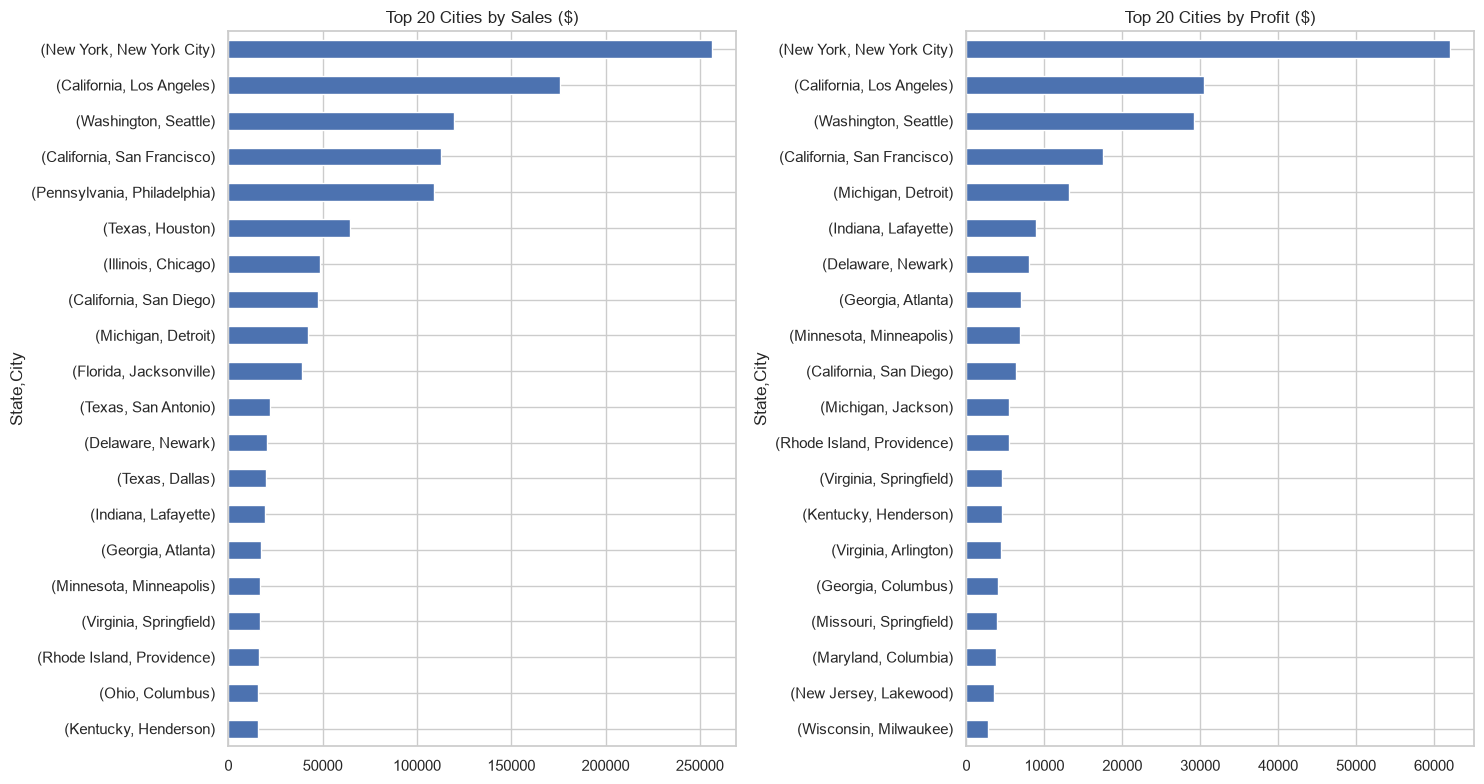

In [6]:
cities=df.groupby(["State","City"])[["Sales","Profit"]].sum()
cities["MarginPct"]=cities["Profit"].div(cities["Sales"])*100
top_sales=cities.nlargest(20,"Sales");top_profit=cities.nlargest(20,"Profit")
display(top_sales);display(top_profit)
print("Villes communes aux deux top 20",len(set(top_sales.index)&set(top_profit.index)))
fig,axes=plt.subplots(1,2,figsize=(15,8))
top_sales["Sales"].sort_values().plot.barh(ax=axes[0],title="Top 20 Cities by Sales ($)")
top_profit["Profit"].sort_values().plot.barh(ax=axes[1],title="Top 20 Cities by Profit ($)")
plt.tight_layout();plt.show()

## Catégories et évolution temporelle

Sales      Profit
Category        Sub-Category                         
Furniture       Bookcases     114879.9963  -3472.5560
                Chairs        328449.1030  26590.1663
                Furnishings    91705.1640  13059.1436
                Tables        206965.5320 -17725.4811
Office Supplies Appliances    107532.1610  18138.0054
                Art            27118.7920   6527.7870
                Binders       203412.7330  30221.7633
                Envelopes      16476.4020   6964.1767
                Fasteners       3024.2800    949.5182
                Labels         12486.3120   5546.2540
                Paper          78479.2060  34053.5693
                Storage       223843.6080  21278.8264
                Supplies       46673.5380  -1189.0995
Technology      Accessories   167380.3180  41936.6357
                Copiers       149528.0300  55617.8249
                Machines      189238.6310   3384.7569
                Phones        330007.0540  44515.7306

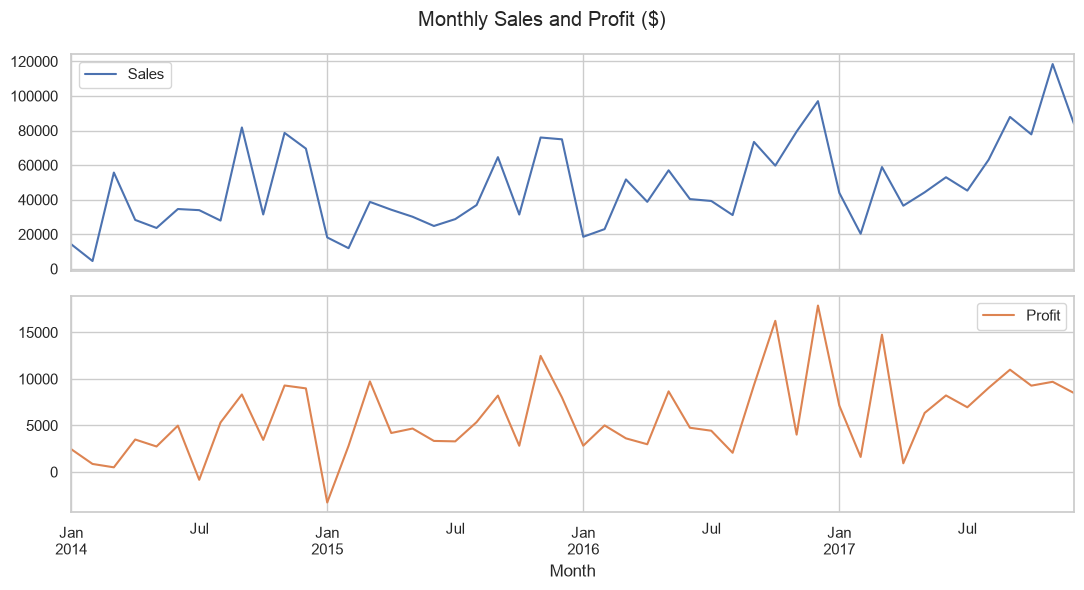

In [7]:
display(df.groupby(["Category","Sub-Category"])[["Sales","Profit"]].sum())
monthly=df.groupby("Month")[["Sales","Profit"]].sum();monthly.index=monthly.index.to_timestamp()
monthly.plot(subplots=True,figsize=(11,6),title="Monthly Sales and Profit ($)");plt.tight_layout();plt.show()

## Décisions marketing fondées sur les résultats

In [8]:
leaders=states.loc[states["Profit"]>0].head(3)
city_leaders=cities.loc[cities["Profit"]>0].nlargest(5,"Profit")
losses=states.loc[states["Profit"]<0].sort_values("Profit")
display(Markdown("- Prioriser les tests d’acquisition dans les grands marchés rentables : "+", ".join(leaders.index)+".\n- Déployer des campagnes locales mesurées dans : "+", ".join(f"{city}, {state}" for state,city in city_leaders.index)+".\n- Auditer remises, assortiment et coûts avant d’augmenter les budgets des États déficitaires : "+", ".join(losses.index)+".\n- Fidéliser les clients rentables, puis mesurer le profit incrémental par expérimentation plutôt que la seule hausse des ventes."))
Path("results").mkdir(exist_ok=True)
states.to_csv("results/state_performance.csv");cities.to_csv("results/city_performance.csv");customers.to_csv("results/customer_performance.csv")

- Prioriser les tests d’acquisition dans les grands marchés rentables : California, New York, Washington.
- Déployer des campagnes locales mesurées dans : New York City, New York, Los Angeles, California, Seattle, Washington, San Francisco, California, Detroit, Michigan.
- Auditer remises, assortiment et coûts avant d’augmenter les budgets des États déficitaires : Texas, Ohio, Pennsylvania, Illinois, North Carolina, Colorado, Tennessee, Arizona, Florida, Oregon.
- Fidéliser les clients rentables, puis mesurer le profit incrémental par expérimentation plutôt que la seule hausse des ventes.

L’historique décrit les commandes observées. Les recommandations sont des priorités à tester, pas une preuve de rendement futur ; coûts marketing, capacité et valeur client future ne figurent pas dans ces données.